# 07MIAR — Redes Neuronales y Deep Learning
## Proyecto de programación: *Deep Vision in classification tasks*

**Actividad:** Comparación de estrategias para la clasificación de imágenes

**Autor(es):** Adelso Steve Araya Solórzano - Fabio Antonio Rodriguez Quesada - Bhuvana Cheemala

**Dataset:** Human Action Recognition (HAR) Dataset   https://www.kaggle.com/datasets/meetnagadia/human-action-recognition-har-dataset

**Problema de clasificación**

## Índice

1. Planteamiento del problema y selección del dataset
2. Carga de datos
3. Inspección y análisis exploratorio
4. Acondicionamiento y preprocesamiento
5. Estrategia 1 — CNN desde cero (*from scratch*)
6. Estrategia 2 — Modelos preentrenados (*transfer learning* y *fine-tuning*)
7. Evaluación y comparación global
8. Conclusiones
9. Referencias y exportación a PDF

**Requisito central:** comparar una CNN entrenada desde cero con, al menos, dos arquitecturas preentrenadas sobre ImageNet. Justificar experimentalmente las decisiones y evaluar finalmente sobre datos no utilizados durante el entrenamiento.

# 1. Planteamiento del problema y selección del dataset

## 1.1 Descripción del problema

**Problema de clasificación:** El problema que se presenta es la identificacion de 24 clases en el lenguaje de señas Americano.

**Aplicación o motivación:** La clasificación de imágenes mediante técnicas de Deep Learning representa una herramienta de gran potencial para automatizar tareas de reconocimiento y análisis visual. La motivación de este proyecto es explorar cómo diferentes arquitecturas de redes neuronales pueden aprender a identificar patrones y clasificar imágenes, comparando el rendimiento de modelos construidos desde cero con modelos preentrenados mediante Transfer Learning. Con ello, se busca comprender las ventajas y limitaciones de cada enfoque, así como evaluar cómo influyen las distintas técnicas de entrenamiento y optimización en la precisión y capacidad de generalización de los modelos.

**Variable objetivo y significado de las clases:** Cada clase identifica una clase de actividades humanas. Las clases que contiene el dataset son:

| Clase | Descripción |
|-------|-------------|
| 0     | calling     |
| 1     | clapping    |
| 2     | cycling     |
| 3     | dancing     |
| 4     | drinking    |
| 5     | eating      |
| 6     | fighting    |
| 7     | hugging     |
| 8     | laughing    |
| 9     | listening_to_music     |
| 10    | running     |
| 11    | sitting     |
| 12    | sleeping    |
| 13    | texting     |
| 14    | using_laptop|


## 1.2 Dataset seleccionado

- Nombre: Human Action Recognition (HAR)
- Fuente y enlace: (https://www.kaggle.com/datasets/meetnagadia/human-action-recognition-har-dataset)
- Estructura de directorios y etiquetas: **TEST:** Dataset/Testing_set.csv  **TRAINING:** Dataset/Training_set.csv . Adicionalmente, existen dos carpetas con las imagenes individuales de cada clase en el directorio Dataset/Train/ y Dataset/Test/ respectivamente.
- Número total de imágenes: 18000 (training data 12600) (test data 5400)
- Número de clases: 15 clases
- Dimensiones y formatos de imagen: las imagenes estan en diferentes formatos, por lo que es necesario pasarlas a un formato común y uniforme antes de entrenar el modelo, por ejemplo, convertirlas a 128x128 RGB con valores de 0-255 por color.

## 1.3 Justificación de la elección

[COMPLETAR: explicar por qué el dataset es adecuado para clasificación y para comparar ambas estrategias.]

In [1]:
# 1.4 Configuración inicial e importaciones
# COMPLETAR: importar las bibliotecas que se utilizarán.
# COMPLETAR: establecer semillas aleatorias para favorecer la reproducibilidad.
# COMPLETAR: definir parámetros generales (rutas, tamaño de imagen, batch size, etc.).

# pip install kagglehub
import pandas as pd

df = pd.read_csv('./Dataset/HumanActionRecognition/Training_set.csv', header=None)
print(df.head())


             0             1
0     filename         label
1  Image_1.jpg       sitting
2  Image_2.jpg  using_laptop
3  Image_3.jpg       hugging
4  Image_4.jpg      sleeping


# 2. Carga del conjunto de datos

## 2.1 Descarga y preparación inicial

El dataset esta disponible en Kaggle para descarga mediante el siguiente link https://www.kaggle.com/datasets/datamunge/sign-language-mnist.

## 2.2 Organización de los datos

[COMPLETAR: describir la estructura de carpetas, ficheros y etiquetas. Explicar cómo se identificarán entrenamiento, validación y test.]
El dataset esta organizado en una carpeta llamada "Dataset" que contiene un subdirectorio llamado "sign_mnist_train" y "sign_mnist_test". En este subdirectorio se encuentran los archivos CSV con las etiquetas correspondientes a cada imagen. La primera columna es el label/etiqueta de la imagen, mientras que el resto de columnas son los valores pixeles de la imagen para un total de 28x28 pixeles o 784 en total.

El dataset se divide en dos partes principales: entrenamiento y test. En este caso, se utiliza un 80% para el entrenamiento y un 20% para el test. Se guardan las variables en X_train, X_test, y_test y y_train, respectivamente.

In [2]:
# COMPLETAR: definir rutas y descargar/preparar el dataset.
# COMPLETAR: implementar, si resulta conveniente, una función reutilizable
# para automatizar la descarga y preparación inicial.
# COMPLETAR: comprobar que las rutas y los ficheros esperados existen.

import random
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt
import cv2
import os
import numpy as np

# 1. Cargar el CSV con Pandas
datos_test = './Dataset/HumanActionRecognition/Training_set.csv'
df = pd.read_csv(datos_test,sep=',')

# 2. Separar características (features) y etiqueta (label)
objetivo = 'label'
X_train = df.drop('label', axis=1)
y_train = df[objetivo]

print(X_train.head(5))
print(y_train.head(5))


      filename
0  Image_1.jpg
1  Image_2.jpg
2  Image_3.jpg
3  Image_4.jpg
4  Image_5.jpg
0         sitting
1    using_laptop
2         hugging
3        sleeping
4    using_laptop
Name: label, dtype: str


In [3]:
# COMPLETAR: cargar los datos y obtener los conjuntos de entrenamiento,
# y test.
# Registrar el número de imágenes y clases de cada partición.

# 1. Cargar el CSV con Pandas
datos_train = './Dataset/HumanActionRecognition/Testing_set.csv'
df = pd.read_csv(datos_train)

# 2. Separar características (features) y etiqueta (label)
X_test = datos_train

print(y_train.head(5))
print(X_train.head(5))
print(X_train.shape)
print(y_train.shape)

0         sitting
1    using_laptop
2         hugging
3        sleeping
4    using_laptop
Name: label, dtype: str
      filename
0  Image_1.jpg
1  Image_2.jpg
2  Image_3.jpg
3  Image_4.jpg
4  Image_5.jpg
(12600, 1)
(12600,)


# 3. Inspección y análisis exploratorio de los datos

## 3.1 Distribución de clases

[COMPLETAR: analizar el número de imágenes por clase e identificar posibles desequilibrios.]

Suma de valores en la columna Objetivo en entrenamiento: label
sitting               840
using_laptop          840
hugging               840
sleeping              840
drinking              840
clapping              840
dancing               840
cycling               840
calling               840
laughing              840
eating                840
fighting              840
listening_to_music    840
running               840
texting               840
Name: count, dtype: int64


C:\Users\Fantr\AppData\Local\Temp\ipykernel_9784\3441247458.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


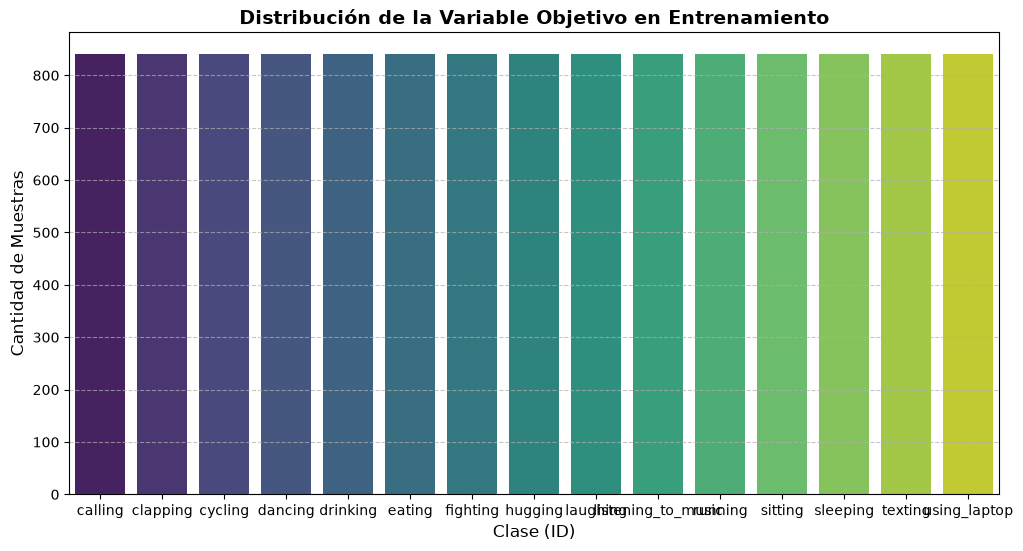

In [4]:
# COMPLETAR: calcular el número de imágenes por clase.
# COMPLETAR: representar gráficamente la distribución de clases.

print(f"Suma de valores en la columna Objetivo en entrenamiento: { y_train.value_counts()}")

df_plot = y_train.value_counts().reset_index(name="cantidad")
df_plot.columns = ["id", "cantidad"]

df_plot = df_plot.sort_values(by="id", ascending=True)

plt.figure(figsize=(12, 6))
sns.barplot(
    x="id",
    y="cantidad",
    data=df_plot,
    order=df_plot["id"],
    palette="viridis",
)

plt.title(
    "Distribución de la Variable Objetivo en Entrenamiento",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Clase (ID)", fontsize=12)
plt.ylabel("Cantidad de Muestras", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

## 3.2 Inspección visual de imágenes

[COMPLETAR: mostrar ejemplos representativos de cada clase e identificar posibles problemas de calidad, variabilidad o etiquetado.]

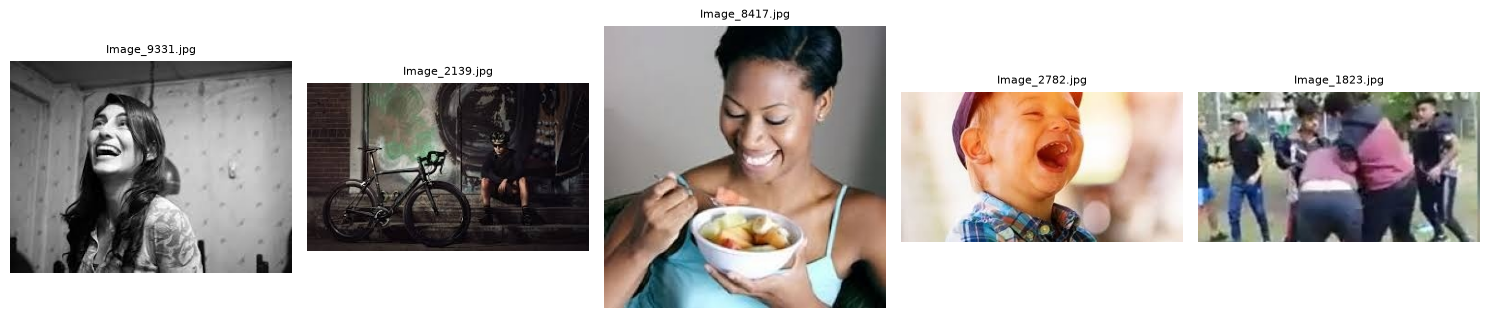

In [5]:
# COMPLETAR: visualizar una selección de imágenes con sus etiquetas.
ruta_carpeta = './Dataset/HumanActionRecognition/train/'

df_azar = X_train.sample(5)

fig, axes = plt.subplots(1, 5, figsize=(15, 5))

for i, filename in enumerate(df_azar['filename']):
    ruta_imagen = os.path.join(ruta_carpeta, filename)
    
    img = cv2.imread(ruta_imagen)
    
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    axes[i].imshow(img_rgb)
    axes[i].set_title(filename, fontsize=8)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 3.3 Conclusiones del análisis exploratorio

[COMPLETAR: resumir los aspectos del dataset que condicionan el preprocesamiento y el diseño de los modelos.]

# 4. Estrategia 1 — CNN desde cero (*from scratch*)

## 4.1 Diseño de la arquitectura inicial

[COMPLETAR: justificar número de bloques convolucionales, filtros, tamaño de kernel, activaciones, pooling y capas finales.]

In [6]:
# COMPLETAR: definir la arquitectura CNN desde cero con TensorFlow/Keras.
# COMPLETAR: mostrar el resumen de la arquitectura.
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder

TAMANO_IMAGEN = (128, 128)

imagenes_procesadas = []

for filename in X_train['filename']:
    ruta_completa = os.path.join(ruta_carpeta, filename)
    img = cv2.imread(ruta_completa)
    
    # Verificamos que la imagen se haya leído correctamente
    if img is not None:
        # REDIMENSIONAR: Cambia el tamaño físicamente sin romper la estructura de la imagen
        img_redimensionada = cv2.resize(img, TAMANO_IMAGEN)
        
        # Guardamos en nuestra lista
        imagenes_procesadas.append(img_redimensionada)

X_train_final = np.array(imagenes_procesadas)

print("Forma final del set de datos:", X_train_final.shape)
print("Forma final del set de datos:", y_train.shape)

X_train_final = X_train_final.astype('float32') / 255.0

cnn_HAR = Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    #layers.Dense(128, activation="relu"),
    layers.Dense(15, activation="softmax")
])

cnn_HAR.summary()

Forma final del set de datos: (12600, 128, 128, 3)
Forma final del set de datos: (12600,)


c:\Users\Fantr\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │       864,015 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 883,407 (3.37 MB)

 Trainable params: 883,407 (3.37 MB)

 Non-trainable params: 0 (0.00 B)

## 4.2 Configuración del entrenamiento

- Optimizador: [COMPLETAR]
- Learning rate: [COMPLETAR]
- Batch size: [COMPLETAR]
- Número de épocas: [COMPLETAR]
- Función de pérdida: [COMPLETAR]
- Métricas: [COMPLETAR]
- Callbacks (si se utilizan): [COMPLETAR]

[COMPLETAR: justificar la configuración elegida.]

In [7]:
encoder = LabelEncoder()
y_train_numerico = encoder.fit_transform(y_train)

print("Etiquetas originales:", y_train.values[:5])
print("Etiquetas numéricas:", y_train_numerico[:5])

Etiquetas originales: <StringArray>
['sitting', 'using_laptop', 'hugging', 'sleeping', 'using_laptop']
Length: 5, dtype: str
Etiquetas numéricas: [11 14  7 12 14]


In [12]:
# COMPLETAR: compilar el modelo.
# COMPLETAR: definir callbacks de monitorización/regularización si procede.
# COMPLETAR: entrenar el modelo y conservar el historial.


cnn_HAR.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_HAR = cnn_HAR.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    validation_split=0.1
)


Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 303ms/step - accuracy: 0.8821 - loss: 0.4023 - val_accuracy: 0.2437 - val_loss: 3.9828
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 300ms/step - accuracy: 0.9222 - loss: 0.2867 - val_accuracy: 0.2683 - val_loss: 4.2417
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 298ms/step - accuracy: 0.9399 - loss: 0.2363 - val_accuracy: 0.2675 - val_loss: 4.7474
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 298ms/step - accuracy: 0.9368 - loss: 0.2373 - val_accuracy: 0.2619 - val_loss: 4.5135
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 299ms/step - accuracy: 0.9737 - loss: 0.1273 - val_accuracy: 0.2595 - val_loss: 5.1299
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 298ms/step - accuracy: 0.9879 - loss: 0.0746 - val_accuracy: 0.2468 - val_loss: 5.2704
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 298ms/step - accuracy: 0.9934 - loss: 0.0489 - val_accuracy: 0.2667 - val_loss: 5.5614
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 299ms/step - accuracy: 0.9974 - loss: 0.0311 - val_accu

## 4.3 Monitorización del entrenamiento

[COMPLETAR: representar las curvas de pérdida y métricas de entrenamiento y validación. Interpretar convergencia, sobreajuste o subajuste.]

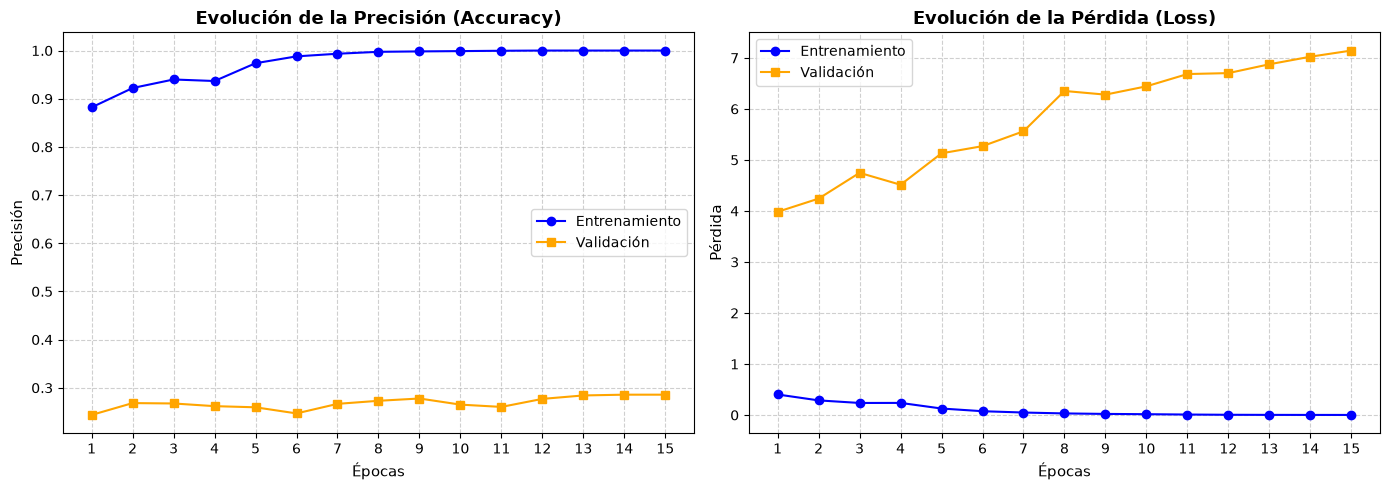

In [13]:
# COMPLETAR: representar las curvas de entrenamiento y validación.

history_dict = history_cnn_HAR.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


## 4.4 Experimentación progresiva y regularización

Realizar experimentos que permitan estudiar el efecto de las decisiones de diseño. Considerar, cuando sea pertinente:

- *Weight regularization*.
- *Dropout*.
- *Batch normalization*.
- *Data augmentation*.
- Cambios en la arquitectura, optimizador o learning rate.

**Experimento 1 — objetivo e hipótesis:** [COMPLETAR]  
**Cambios respecto al experimento anterior:** [COMPLETAR]  
**Resultados observados:** [COMPLETAR]  
**Interpretación y decisión para el siguiente experimento:** [COMPLETAR]

c:\Users\Fantr\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,394,255 (28.21 MB)

 Trainable params: 7,394,255 (28.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 382ms/step - accuracy: 0.1095 - loss: 3.1436 - val_accuracy: 0.1968 - val_loss: 2.6203
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 33s 370ms/step - accuracy: 0.2015 - loss: 2.6227 - val_accuracy: 0.2452 - val_loss: 2.5940
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 33s 373ms/step - accuracy: 0.2486 - loss: 2.5435 - val_accuracy: 0.2659 - val_loss: 2.5174
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 381ms/step - accuracy: 0.2762 - loss: 2.4893 - val_accuracy: 0.2857 - val_loss: 2.4669
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 33s 372ms/step - accuracy: 0.3039 - loss: 2.4299 - val_accuracy: 0.3048 - val_loss: 2.4650
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 33s 372ms/step - accuracy: 0.3273 - loss: 2.3784 - val_accuracy: 0.3317 - val_loss: 2.4220
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 382ms/step - accuracy: 0.3467 - loss: 2.3463 - val_accuracy: 0.3317 - val_loss: 2.4345
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 386ms/step - accuracy: 0.3638 - loss: 2.3132 - val_accu

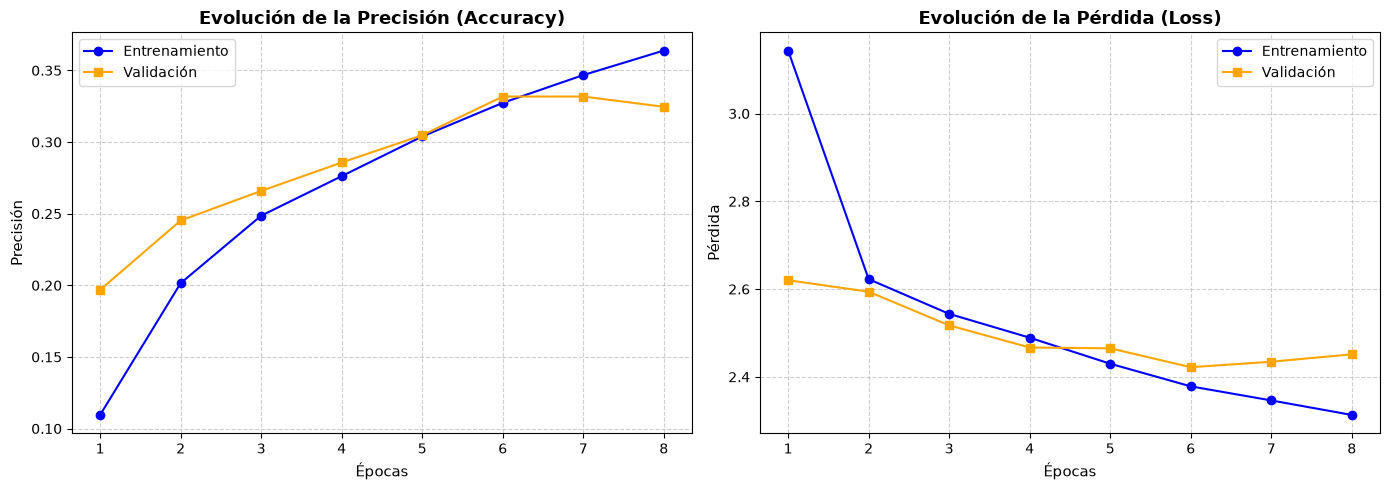

In [14]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ #agregue una capa dropout y una extra de densas
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),  # Agregamos Dropout para prevenir overfitting


    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)), # Agregamos regularizadores L2 para prevenir overfitting y estabilidad en la red
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)


cnn_HAR_dropout_dense.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_26 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_13 (Flatten)            │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,394,255 (28.21 MB)

 Trainable params: 7,394,255 (28.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 36s 403ms/step - accuracy: 0.1346 - loss: 3.8542 - val_accuracy: 0.2302 - val_loss: 2.9624
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 395ms/step - accuracy: 0.2391 - loss: 2.7366 - val_accuracy: 0.2659 - val_loss: 2.5769
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 398ms/step - accuracy: 0.2966 - loss: 2.4868 - val_accuracy: 0.2817 - val_loss: 2.4668
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 397ms/step - accuracy: 0.3217 - loss: 2.3751 - val_accuracy: 0.2960 - val_loss: 2.4090
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 37s 418ms/step - accuracy: 0.3464 - loss: 2.2987 - val_accuracy: 0.3103 - val_loss: 2.3685
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 38s 423ms/step - accuracy: 0.3647 - loss: 2.2318 - val_accuracy: 0.3056 - val_loss: 2.3459
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 36s 408ms/step - accuracy: 0.3820 - loss: 2.1834 - val_accuracy: 0.3071 - val_loss: 2.3326
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 394ms/step - accuracy: 0.4003 - loss: 2.1462 - val_accu

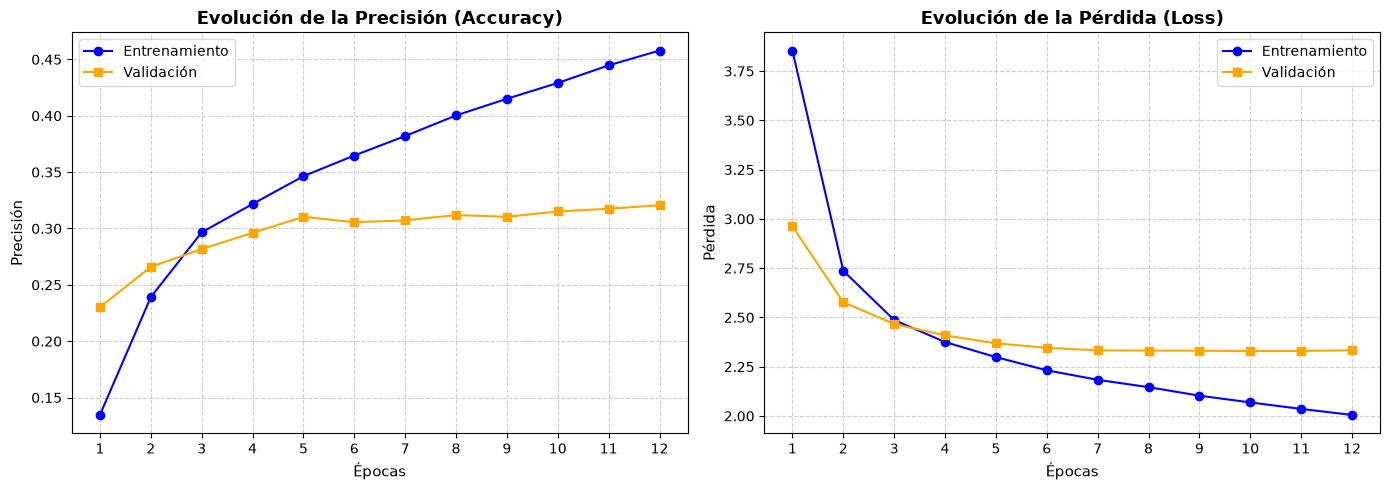

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)),
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

optimizer = Adam(learning_rate=0.0001) # Se agrego un learning rate diferente para el optimizador Adam

cnn_HAR_dropout_dense.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


c:\Users\Fantr\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,394,255 (28.21 MB)

 Trainable params: 7,394,255 (28.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 36s 403ms/step - accuracy: 0.0858 - loss: 3.3225 - val_accuracy: 0.1151 - val_loss: 3.0152
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 395ms/step - accuracy: 0.1250 - loss: 2.8880 - val_accuracy: 0.1556 - val_loss: 2.7720
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 398ms/step - accuracy: 0.1707 - loss: 2.6918 - val_accuracy: 0.2032 - val_loss: 2.6070
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 398ms/step - accuracy: 0.2039 - loss: 2.5634 - val_accuracy: 0.2183 - val_loss: 2.5228
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 398ms/step - accuracy: 0.2311 - loss: 2.4748 - val_accuracy: 0.2286 - val_loss: 2.4645
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 36s 399ms/step - accuracy: 0.2468 - loss: 2.4135 - val_accuracy: 0.2389 - val_loss: 2.4194
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 389ms/step - accuracy: 0.2623 - loss: 2.3626 - val_accuracy: 0.2492 - val_loss: 2.3898
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 385ms/step - accuracy: 0.2794 - loss: 2.3216 - val_accu

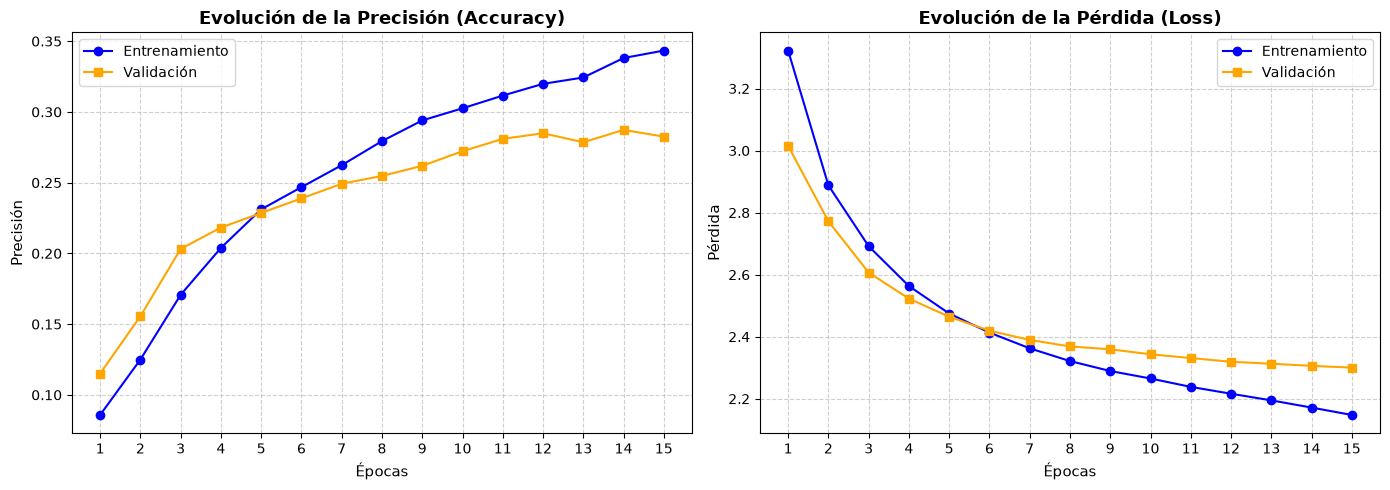

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.004)), # Cambio de tasa para el regularizador
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

optimizer = Adam(learning_rate=0.0001)

cnn_HAR_dropout_dense.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 61, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,795,407 (25.92 MB)

 Trainable params: 6,795,407 (25.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.1181 - loss: 3.9881 - val_accuracy: 0.1849 - val_loss: 3.0864
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.2030 - loss: 2.8210 - val_accuracy: 0.2556 - val_loss: 2.6235
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.2667 - loss: 2.5270 - val_accuracy: 0.2857 - val_loss: 2.4753
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.2955 - loss: 2.3985 - val_accuracy: 0.3008 - val_loss: 2.3836
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.3183 - loss: 2.3075 - val_accuracy: 0.3119 - val_loss: 2.3235
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.3363 - loss: 2.2371 - val_accuracy: 0.3325 - val_loss: 2.2814
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.3612 - loss: 2.1730 - val_accuracy: 0.3373 - val_loss: 2.2520
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.3806 - loss: 2.1192 - val_accuracy: 0.3476 - v

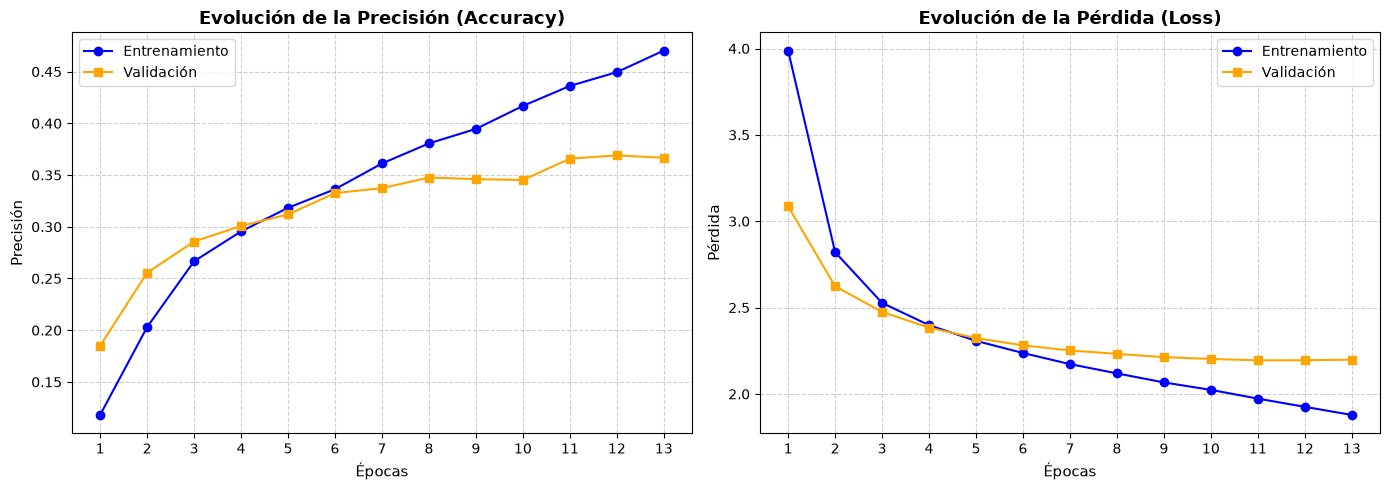

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Conv2D(64, (3, 3), activation="relu", input_shape=(128, 128, 3)), # Aumento de la red de 32 --> 64
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"), # Aumento de la red de 64 --> 128
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), activation="relu"), # Creacion de una nueva capa convolucional para aumentar la capacidad de aprendizaje 256
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)), # Volvemos a la tasa anterior porque obtuvimos peores resultados
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

optimizer = Adam(learning_rate=0.0001)

cnn_HAR_dropout_dense.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 61, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_16 (Flatten)            │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,795,407 (25.92 MB)

 Trainable params: 6,795,407 (25.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.0698 - loss: 3.1263 - val_accuracy: 0.1484 - val_loss: 2.6559 - learning_rate: 0.0010
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.1614 - loss: 2.5881 - val_accuracy: 0.2040 - val_loss: 2.5001 - learning_rate: 0.0010
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.2152 - loss: 2.4926 - val_accuracy: 0.2381 - val_loss: 2.4528 - learning_rate: 0.0010
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.2592 - loss: 2.4055 - val_accuracy: 0.2794 - val_loss: 2.3242 - learning_rate: 0.0010
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.2995 - loss: 2.3109 - val_accuracy: 0.3151 - val_loss: 2.2633 - learning_rate: 0.0010
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.3334 - loss: 2.2261 - val_accuracy: 0.3310 - val_loss: 2.2297 - learning_rate: 0.0010
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.3551 - loss: 2.1754 - val_acc

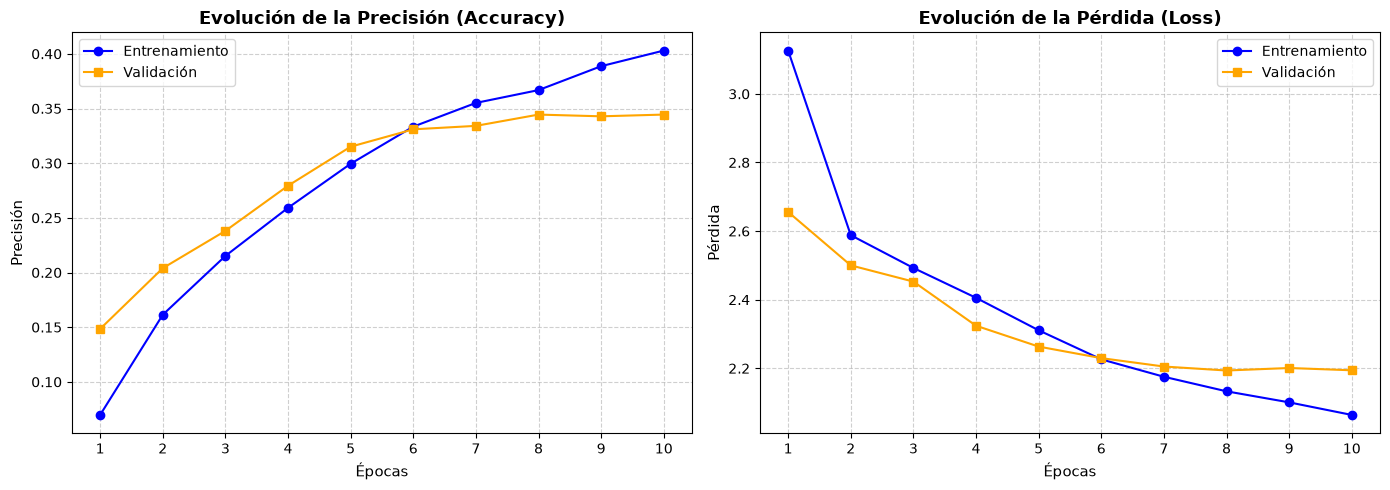

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Conv2D(64, (3, 3), activation="relu", input_shape=(128, 128, 3)), # Aumento de la red de 32 --> 64
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"), # Aumento de la red de 64 --> 128
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), activation="relu"), # Creacion de una nueva capa convolucional para aumentar la capacidad de aprendizaje 256
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)), # Volvemos a la tasa anterior porque obtuvimos peores resultados
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

lr_scheduler = callbacks.ReduceLROnPlateau( # Agregamos un LR Scheduler para mejora dinamica del LR
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

#optimizer = Adam(learning_rate=0.0001)

cnn_HAR_dropout_dense.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop, lr_scheduler],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


In [15]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

data_augmentation = Sequential([ # Implementando data augmentation para mas variedad de imagenes en el dataset
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(factor=0.1),
    layers.RandomContrast(factor=0.1),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1)
])

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Input(shape=(128, 128, 3)), #Nueva capa Input al inicio de la red

    data_augmentation,

    layers.Conv2D(128, (3, 3), activation="relu"), # Aumento de la red de 64 --> 128
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), activation="relu"), # Aumento de la red de 128 --> 256
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), activation="relu"), # Creacion de una nueva capa convolucional para aumentar la capacidad de aprendizaje 256
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)), # Volvemos a la tasa anterior porque obtuvimos peores resultados
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

lr_scheduler = callbacks.ReduceLROnPlateau( # Agregamos un LR Scheduler para mejora dinamica del LR
    monitor='val_loss',
    factor=0.2,
    patience=6, # Aumento de la paciencia por el data augmentation
    min_lr=1e-6,
    verbose=1
)

#optimizer = Adam(learning_rate=0.0001)

cnn_HAR_dropout_dense.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=40, # Aumento de epocas por el data augmentation
    batch_size=128,
    callbacks=[early_stop, lr_scheduler],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_6 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 126, 126, 128)  │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 63, 63, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 61, 61, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 30, 30, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,313,423 (27.90 MB)

 Trainable params: 7,313,423 (27.90 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 318s 4s/step - accuracy: 0.0637 - loss: 6.4451 - val_accuracy: 0.0579 - val_loss: 4.5172 - learning_rate: 0.0010
Epoch 2/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 317s 4s/step - accuracy: 0.0642 - loss: 4.0457 - val_accuracy: 0.0579 - val_loss: 3.6789 - learning_rate: 0.0010
Epoch 3/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 321s 4s/step - accuracy: 0.0645 - loss: 3.4597 - val_accuracy: 0.0579 - val_loss: 3.2791 - learning_rate: 0.0010
Epoch 4/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 323s 4s/step - accuracy: 0.0620 - loss: 3.1603 - val_accuracy: 0.0563 - val_loss: 3.0608 - learning_rate: 0.0010
Epoch 5/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 322s 4s/step - accuracy: 0.0632 - loss: 2.9912 - val_accuracy: 0.0563 - val_loss: 2.9331 - learning_rate: 0.0010
Epoch 6/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 317s 4s/step - accuracy: 0.0650 - loss: 2.8900 - val_accuracy: 0.0563 - val_loss: 2.8548 - learning_rate: 0.0010
Epoch 7/40
89/89 ━━━━━━━━━━━━━━━━━━━━ 318s 4s/step - accuracy: 0.0648 - loss: 2.8270 - val_acc

: 

## 4.5 Selección del modelo *from scratch*

[COMPLETAR: identificar el modelo seleccionado y justificarlo a partir de los resultados de validación y del comportamiento durante el entrenamiento.]

In [ ]:
# COMPLETAR: recuperar/cargar el modelo seleccionado para la evaluación final.


# 5. Estrategia 2 — Modelos preentrenados

Se deberán comparar **al menos dos arquitecturas CNN preentrenadas sobre ImageNet**. Para cada una, documentar *transfer learning* y *fine-tuning*, además de los experimentos realizados.

## 5.1 Decisiones comunes

- Resolución de entrada: [COMPLETAR]
- Preprocesamiento específico de cada arquitectura: [COMPLETAR]
- Pesos iniciales: [COMPLETAR]
- Estrategia para congelar/descongelar capas: [COMPLETAR]
- Clasificador final: [COMPLETAR]
- Regularización y *data augmentation*: [COMPLETAR]

[COMPLETAR: justificar las decisiones comunes y las diferencias entre arquitecturas.]

## 5.2 Arquitectura preentrenada 1 — [NOMBRE]

### Selección y descripción

[COMPLETAR: nombre, características relevantes y justificación de la elección.]

### Fase A — Transfer learning

[COMPLETAR: indicar qué capas permanecen congeladas, cómo se entrena el clasificador y por qué.]

In [ ]:
# COMPLETAR: cargar la arquitectura preentrenada con pesos ImageNet.
# COMPLETAR: adaptar la parte clasificadora al número de clases.
# COMPLETAR: mostrar el resumen del modelo.


In [ ]:
# COMPLETAR: compilar y entrenar la fase de transfer learning.
# COMPLETAR: conservar el historial de entrenamiento.


### Monitorización de transfer learning

[COMPLETAR: representar e interpretar las curvas y métricas.]

In [ ]:
# COMPLETAR: representar las curvas de entrenamiento y validación.


### Fase B — Fine-tuning

[COMPLETAR: explicar qué capas se descongelan, si se hace progresivamente y qué learning rate se utiliza.]

In [ ]:
# COMPLETAR: configurar el fine-tuning, recompilar y entrenar.
# COMPLETAR: guardar el historial y el modelo resultante.


### Análisis de la arquitectura

[COMPLETAR: comparar transfer learning frente a fine-tuning y justificar la configuración seleccionada.]

## 5.3 Arquitectura preentrenada 2 — [NOMBRE]

### Selección y descripción

[COMPLETAR: nombre, características relevantes y justificación de la elección.]

### Fase A — Transfer learning

[COMPLETAR: indicar qué capas permanecen congeladas, cómo se entrena el clasificador y por qué.]

In [ ]:
# COMPLETAR: cargar la arquitectura preentrenada con pesos ImageNet.
# COMPLETAR: adaptar la parte clasificadora al número de clases.
# COMPLETAR: mostrar el resumen del modelo.


In [ ]:
# COMPLETAR: compilar y entrenar la fase de transfer learning.
# COMPLETAR: conservar el historial de entrenamiento.


### Monitorización de transfer learning

[COMPLETAR: representar e interpretar las curvas y métricas.]

In [ ]:
# COMPLETAR: representar las curvas de entrenamiento y validación.


### Fase B — Fine-tuning

[COMPLETAR: explicar qué capas se descongelan, si se hace progresivamente y qué learning rate se utiliza.]

In [ ]:
# COMPLETAR: configurar el fine-tuning, recompilar y entrenar.
# COMPLETAR: guardar el historial y el modelo resultante.


### Análisis de la arquitectura

[COMPLETAR: comparar transfer learning frente a fine-tuning y justificar la configuración seleccionada.]

## 5.4 Comparación de arquitecturas preentrenadas

[COMPLETAR: comparar ambas arquitecturas con las mismas particiones y métricas. Analizar rendimiento, coste computacional y generalización.]

In [ ]:
# COMPLETAR: preparar una tabla comparativa con los resultados de las
# arquitecturas preentrenadas y sus variantes (transfer learning/fine-tuning).


# 6. Evaluación y comparación global de estrategias

## 6.1 Evaluación final sobre test

[COMPLETAR: evaluar únicamente los modelos seleccionados sobre el conjunto de test. No utilizar test para tomar decisiones durante el entrenamiento.]

In [ ]:
# COMPLETAR: evaluar el modelo from scratch sobre test.
# COMPLETAR: evaluar los modelos preentrenados seleccionados sobre test.
# COMPLETAR: registrar las métricas generadas durante la ejecución.


## 6.2 Métricas y análisis por clase

[COMPLETAR: incluir métricas apropiadas para el problema. Considerar matriz de confusión, precision, recall, F1-score y métricas por clase cuando proceda.]

In [ ]:
# COMPLETAR: generar matrices de confusión y métricas por clase.
# COMPLETAR: generar las visualizaciones correspondientes.


## 6.3 Comparación de resultados

Comparar, como mínimo:

- Rendimiento sobre el conjunto de test.
- Evolución del entrenamiento y validación.
- Capacidad de generalización.
- Evidencias de sobreajuste o subajuste.
- Tiempo/coste de entrenamiento, si se ha medido.
- Ventajas e inconvenientes de cada estrategia.

**Análisis:** [COMPLETAR]

In [ ]:
# COMPLETAR: construir una tabla o visualización comparativa final
# con métricas obtenidas durante la ejecución.


## 6.4 Errores y ejemplos de predicción

[COMPLETAR: inspeccionar ejemplos correctamente e incorrectamente clasificados. Analizar patrones de error y posibles causas.]

In [ ]:
# COMPLETAR: visualizar ejemplos de predicciones y errores del modelo.


# 7. Conclusiones

## 7.1 Mejor modelo y estrategia

[COMPLETAR: indicar qué modelo ofrece la mejor solución y justificar la elección con resultados de test y evidencias experimentales.]

## 7.2 Aprendizajes y análisis crítico

[COMPLETAR: explicar qué decisiones tuvieron mayor impacto, qué técnicas ayudaron o no y qué limitaciones se encontraron.]

## 7.3 Posibles mejoras futuras

[COMPLETAR]

# 8. Referencias

[COMPLETAR: incluir referencias al dataset, documentación de TensorFlow/Keras, artículos y recursos utilizados.]

# 9. Lista de comprobación y exportación a PDF

Antes de entregar:

- [ ] Todas las secciones están completadas.
- [ ] El código se ha ejecutado y no quedan errores.
- [ ] Se muestran evidencias de entrenamiento real para todos los modelos presentados.
- [ ] Las métricas y figuras proceden de la ejecución del notebook.
- [ ] El conjunto de test se ha reservado para la evaluación final.
- [ ] Las conclusiones están respaldadas por los experimentos.
- [ ] El PDF incluye explicaciones, código ejecutado, resultados y figuras.

**Exportación:** generar el PDF directamente desde el notebook de Colab, de modo que se incluyan las celdas y sus salidas. La conversión mediante `nbconvert` puede requerir dependencias LaTeX adicionales.

In [ ]:
# COMPLETAR: si se desea automatizar la exportación a PDF desde Colab,
# configurar aquí las rutas y comandos necesarios.
